## Libraries

In [1]:
# Import needed libraries

import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

from pathlib import Path
from scipy.spatial.distance import jensenshannon
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, mean_absolute_percentage_error
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.stattools import grangercausalitytests

# statsmodels turns its own warnings back on when it is imported, so this has to come after the imports.
warnings.filterwarnings('ignore')

## Figure Theme

In [2]:
# Colors and plot style used for every figure so they match the white paper.
NAVY = '#223343'
TAN = '#B5A093'
ORANGE = '#D9772B'
TEAL = '#3C8D93'
GREY = '#8A8F94'

plt.rcParams.update({
    'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.alpha': 0.25, 'font.family': 'serif',
    'axes.titleweight': 'bold', 'axes.titlesize': 12, 'axes.labelsize': 10,
})

# Makes the printed tables wide enough to read.
pd.set_option('display.width', 170)
pd.set_option('display.max_columns', 30)

## Loading Data

In [3]:
# Looks for each data file in this folder, a data folder, or the parent folder.
data_folders = [
    Path('.'),
    Path('data'),
    Path('..'),
    Path('..') / 'data'
]
file_names = ['complaints-by-airport.csv', 'complaints-by-category.csv', 'complaints-by-subcategory.csv']

data_paths = []
for file_name in file_names:
    found = [folder / file_name for folder in data_folders if (folder / file_name).exists()]
    if not found:
        raise FileNotFoundError(f'{file_name} not found. It is in the data folder of this repository. Source: https://github.com/data-liberation-project/tsa-complaint-counts')
    data_paths.append(found[0])

# keep_default_na=False keeps a blank airport as a blank string instead of turning it into a missing value.
airport = pd.read_csv(data_paths[0], keep_default_na=False)
category = pd.read_csv(data_paths[1], keep_default_na=False)
subcategory = pd.read_csv(data_paths[2], keep_default_na=False)

print(f"airport file:     {len(airport):>9,} rows x {airport.shape[1]} columns")
print(f"category file:    {len(category):>9,} rows x {category.shape[1]} columns")
print(f"subcategory file: {len(subcategory):>9,} rows x {subcategory.shape[1]} columns")
print(airport.head())

airport file:        41,721 rows x 4 columns
category file:      241,588 rows x 7 columns
subcategory file:   504,512 rows x 11 columns
  pdf_report_date airport year_month  count
0         2019-02     ABE    2015-01      0
1         2019-02     ABE    2015-02      0
2         2019-02     ABE    2015-03      0
3         2019-02     ABE    2015-04      0
4         2019-02     ABE    2015-05      2


## Cleaning Data

In [4]:
# Turns year_month into a real date (the first of each month) so the data can be treated as a time series.
airport['date'] = pd.to_datetime(airport['year_month'] + '-01')
category['date'] = pd.to_datetime(category['year_month'] + '-01')
subcategory['date'] = pd.to_datetime(subcategory['year_month'] + '-01')

# Some complaints are not tied to any airport and have a blank airport. Instead of dropping them,
# they are labeled UNATTRIBUTED so nothing is silently removed.
airport['airport'] = airport['airport'].replace('', 'UNATTRIBUTED')
category['airport'] = category['airport'].replace('', 'UNATTRIBUTED')
subcategory['airport'] = subcategory['airport'].replace('', 'UNATTRIBUTED')

print("Blank airports left after labeling:", (airport['airport'] == '').sum())

Blank airports left after labeling: 0


## Data Exploration

In [5]:
# Checks each file for duplicate rows (same airport, category, and month) and negative counts.
print("\nDUPLICATE KEYS\n")
print("Airport file:", airport.duplicated(['airport', 'date']).sum())
print("Category file:", category.duplicated(['airport', 'category', 'date']).sum())

# The subcategory file has 8,289 repeated keys, but the counts are different, so they are separate
# line items and get added together instead of dropped.
print("Subcategory file:", subcategory.duplicated(['airport', 'category', 'subcategory', 'date']).sum())

print("\nNEGATIVE COUNTS\n")
print("Airport file:", (airport['count'] < 0).sum())
print("Category file:", (category['count'] < 0).sum())
print("Subcategory file:", (subcategory['count'] < 0).sum())

# All three files describe the same complaints, so they should add up to the same total (1,021,281).
print("\nTOTAL COMPLAINTS\n")
print("Airport file:", f"{airport['count'].sum():,}")
print("Category file:", f"{category['count'].sum():,}")
print("Subcategory file:", f"{subcategory['count'].sum():,}")

# Compares the monthly totals across the three files. There should be 109 months and no disagreements.
airport_monthly = airport.groupby('date')['count'].sum()
category_monthly_total = category.groupby('date')['count'].sum()
subcategory_monthly_total = subcategory.groupby('date')['count'].sum()
disagree = (airport_monthly != category_monthly_total) | (airport_monthly != subcategory_monthly_total)

print("\nMonths in the data:", len(airport_monthly))
print("Complete month grid (Jan 2015 to Jan 2024):", pd.date_range('2015-01-01', '2024-01-01', freq='MS').equals(airport_monthly.index))
print("Months where the three files disagree:", disagree.sum())


DUPLICATE KEYS

Airport file: 0
Category file: 0


Subcategory file: 8289

NEGATIVE COUNTS

Airport file: 0
Category file: 0
Subcategory file: 0

TOTAL COMPLAINTS

Airport file: 1,021,281
Category file: 1,021,281
Subcategory file: 1,021,281

Months in the data: 109
Complete month grid (Jan 2015 to Jan 2024): True
Months where the three files disagree: 0


In [6]:
# Looks at how many complaints have no airport. They are one row per month.
unattributed = airport[airport['airport'] == 'UNATTRIBUTED']
named = airport[airport['airport'] != 'UNATTRIBUTED']

print(f"Unattributed rows: {len(unattributed)} (one per month)")
print(f"Unattributed complaints: {unattributed['count'].sum():,} ({unattributed['count'].sum() / airport['count'].sum():.1%} of all complaints)")

# Complaints by year, split into the ones tied to an airport and the ones that are not.
airport['year'] = airport['date'].dt.year
airport['tied_to_airport'] = airport['airport'] != 'UNATTRIBUTED'
yearly = airport.pivot_table(index='year', columns='tied_to_airport', values='count', aggfunc='sum')
yearly.columns = ['Unattributed', 'Attributed to an airport']
yearly['Total'] = yearly['Unattributed'] + yearly['Attributed to an airport']
yearly['Attributed share'] = yearly['Attributed to an airport'] / yearly['Total']

print("\nComplaints by year (2024 is January only):")
print(yearly.round(3).to_string(formatters={c: '{:,.0f}'.format for c in ['Unattributed', 'Attributed to an airport', 'Total']}))

Unattributed rows: 109 (one per month)
Unattributed complaints: 437,786 (42.9% of all complaints)

Complaints by year (2024 is January only):
     Unattributed Attributed to an airport   Total  Attributed share
year                                                                
2015       48,933                   44,548  93,481             0.477
2016       59,502                   57,212 116,714             0.490
2017       52,795                   53,757 106,552             0.505
2018       62,771                   52,571 115,342             0.456
2019       63,153                   49,457 112,610             0.439
2020       24,480                   20,846  45,326             0.460
2021       33,147                   47,886  81,033             0.591
2022       45,321                  120,555 165,876             0.727
2023       44,368                  128,361 172,729             0.743
2024        3,316                    8,302  11,618             0.715


In [7]:
# Counts how many of the 109 months each named airport reports.
months_reported = named.groupby('airport')['date'].nunique()
full_coverage = months_reported[months_reported == 109].index

print(f"Named airports: {len(months_reported)} | reporting all 109 months: {(months_reported == 109).sum()} | partial coverage: {(months_reported < 109).sum()}")

# The airports with all 109 months hold almost all of the named-airport complaints (98.1%).
print(f"Full-coverage airports hold {named[named['airport'].isin(full_coverage)]['count'].sum() / named['count'].sum():.1%} of named-airport complaints")

# The category file has 49 raw category labels and 47 after the Data Liberation Project cleaned them.
print(f"Category labels: {category['category'].nunique()} raw -> {category['clean_cat'].nunique()} after cleaning")

Named airports: 448 | reporting all 109 months: 228 | partial coverage: 220
Full-coverage airports hold 98.1% of named-airport complaints
Category labels: 49 raw -> 47 after cleaning


## Visualizations

Lowest month:  Apr 2020 (781)
Highest month: Mar 2022 (16,181)


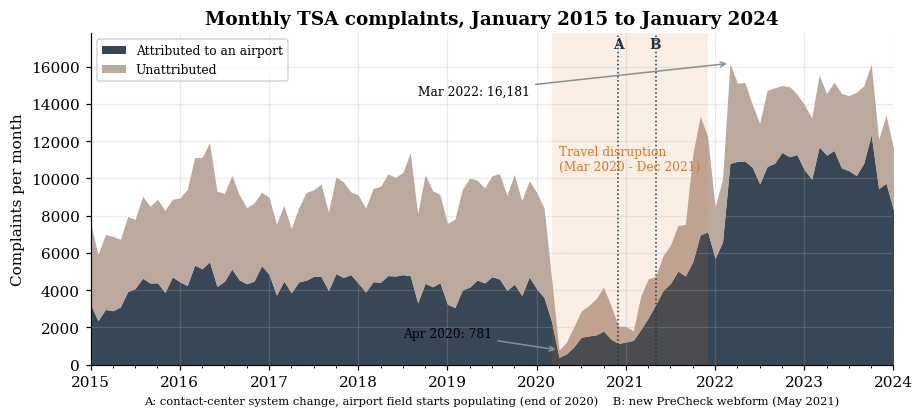

In [8]:
# Monthly complaints, split into the ones tied to an airport and the ones that are not.
monthly = airport.pivot_table(index='date', columns='tied_to_airport', values='count', aggfunc='sum').asfreq('MS')
monthly.columns = ['Unattributed', 'Attributed to an airport']
monthly = monthly[['Attributed to an airport', 'Unattributed']]

# y is the national total for each month. It is used for the forecasting section.
y = monthly.sum(axis=1).astype(float)

# The lowest month is April 2020 (781 complaints) and the highest is March 2022 (16,181).
low = y.idxmin()
high = y.idxmax()
print(f"Lowest month:  {low:%b %Y} ({y[low]:,.0f})")
print(f"Highest month: {high:%b %Y} ({y[high]:,.0f})")

# Figure 1: monthly complaints with the travel disruption shaded and the two collection changes marked A and B.
fig, ax = plt.subplots(figsize=(8.5, 3.9))
monthly.plot.area(ax=ax, color=[NAVY, TAN], alpha=0.9, linewidth=0)
ax.axvspan(pd.Timestamp('2020-03-01'), pd.Timestamp('2021-12-01'), color=ORANGE, alpha=0.12, lw=0)
ax.text(pd.Timestamp('2020-04-15'), 11800, 'Travel disruption\n(Mar 2020 - Dec 2021)', fontsize=8, color=ORANGE, va='top')
ax.annotate(f'{low:%b %Y}: {y[low]:,.0f}', xy=(low, y[low]), xytext=(pd.Timestamp('2018-07-01'), 1500),
            arrowprops=dict(arrowstyle='->', color=GREY), fontsize=8)
ax.annotate(f'{high:%b %Y}: {y[high]:,.0f}', xy=(high, y[high]), xytext=(pd.Timestamp('2018-09-01'), 14500),
            arrowprops=dict(arrowstyle='->', color=GREY), fontsize=8)
ax.set_ylim(0, 17800)
for when, tag in [('2020-12-01', 'A'), ('2021-05-01', 'B')]:
    ax.axvline(pd.Timestamp(when), color=NAVY, ls=':', lw=1)
    ax.text(pd.Timestamp(when), 17000, tag, ha='center', fontsize=9, fontweight='bold', color=NAVY)
ax.set_title('Monthly TSA complaints, January 2015 to January 2024')
ax.set_xlabel('A: contact-center system change, airport field starts populating (end of 2020)    B: new PreCheck webform (May 2021)', fontsize=7.5)
ax.set_ylabel('Complaints per month')
ax.legend(title='', loc='upper left', fontsize=8)
plt.tight_layout()
plt.show()

## Forecasting Model Data Preperation

In [9]:
# Monthly complaints for each category. This is also used later for the leading indicators and the mix shift.
category_monthly = category.groupby(['date', 'clean_cat'])['count'].sum().unstack(fill_value=0).asfreq('MS')
all_complaints = category_monthly.sum(axis=1)

# PreCheck is the category called Expedited Passenger Screening Program.
precheck = category_monthly['Expedited Passenger Screening Program']

# The same comparison is run on two series: all complaints, and everything except PreCheck.
# The second one is only looked at in the PreCheck Sensitivity Check at the end.
series_to_forecast = {'All complaints': y, 'Without PreCheck': (all_complaints - precheck).astype(float)}

# The last 24 months are the one-month-ahead targets.
targets = y.index[-24:]
print(f"One-month-ahead targets: {targets[0]:%b %Y} to {targets[-1]:%b %Y}")

One-month-ahead targets: Feb 2022 to Jan 2024


## Training and Comparing Models

In [10]:
# Forecasts and scores for each series are saved in these dictionaries.
one_step_forecasts = {}
results_by_series = {}

for series_name, series in series_to_forecast.items():

    # ---------- One month ahead, rolling forward over the last 24 months ----------
    # Empty lists hold each model's forecast for every target month.
    naive_list, seasonal_list, avg12_list = [], [], []
    hw_list, sarima_diff_list, sarima_ar_list, rf_list = [], [], [], []

    for target in targets:

        # Only the months before the target are used for training.
        train = series[:target - pd.offsets.MonthBegin(1)]

        # Naive: the forecast is the same as last month.
        naive_list.append(train.iloc[-1])

        # Seasonal naive: the forecast is the same month last year.
        seasonal_list.append(train.iloc[-12])

        # Average of the last 12 months.
        avg12_list.append(train.iloc[-12:].mean())

        # Holt-Winters exponential smoothing with a damped trend and yearly seasonality.
        hw_fit = ExponentialSmoothing(train, trend='add', damped_trend=True, seasonal='add', seasonal_periods=12).fit()
        hw_list.append(hw_fit.forecast(1).iloc[0])

        # SARIMA (1,1,1)(0,1,1,12) on the log of the counts. It differences away the trend and seasonality.
        sarima_diff_fit = SARIMAX(np.log1p(train), order=(1, 1, 1), seasonal_order=(0, 1, 1, 12)).fit(disp=False)
        sarima_diff_list.append(np.expm1(sarima_diff_fit.forecast(1).iloc[0]))

        # SARIMA (1,0,0)(1,0,0,12) without differencing, as a contrast.
        sarima_ar_fit = SARIMAX(np.log1p(train), order=(1, 0, 0), seasonal_order=(1, 0, 0, 12)).fit(disp=False)
        sarima_ar_list.append(np.expm1(sarima_ar_fit.forecast(1).iloc[0]))

        # Random Forest on the last 3 months plus the calendar month (as a sine and cosine so December sits next to January).
        values = list(train.values)
        months = list(train.index.month)
        features = []
        for i in range(3, len(values)):
            features.append(values[i - 3:i] + [np.sin(2 * np.pi * months[i] / 12), np.cos(2 * np.pi * months[i] / 12)])
        rf_model = RandomForestRegressor(n_estimators=200, min_samples_leaf=2, random_state=42).fit(features, values[3:])
        next_features = values[-3:] + [np.sin(2 * np.pi * target.month / 12), np.cos(2 * np.pi * target.month / 12)]
        rf_list.append(rf_model.predict([next_features])[0])

    one_step = pd.DataFrame({'Naive (last month)': naive_list,
                             'Seasonal naive': seasonal_list,
                             'Average of last 12 months': avg12_list,
                             'Holt-Winters (damped, seasonal)': hw_list,
                             'SARIMA (1,1,1)(0,1,1,12)': sarima_diff_list,
                             'SARIMA (1,0,0)(1,0,0,12)': sarima_ar_list,
                             'Random Forest on lags': rf_list}, index=targets)

    # ---------- 12-month holdout: train through January 2023 and forecast the next 12 months ----------
    train = series.iloc[:-12]
    test = series.iloc[-12:]

    twelve = pd.DataFrame(index=test.index)
    twelve['Naive (last month)'] = train.iloc[-1]
    twelve['Seasonal naive'] = train.iloc[-12:].values
    twelve['Average of last 12 months'] = train.iloc[-12:].mean()
    twelve['Holt-Winters (damped, seasonal)'] = ExponentialSmoothing(train, trend='add', damped_trend=True, seasonal='add', seasonal_periods=12).fit().forecast(12).values
    twelve['SARIMA (1,1,1)(0,1,1,12)'] = np.expm1(SARIMAX(np.log1p(train), order=(1, 1, 1), seasonal_order=(0, 1, 1, 12)).fit(disp=False).forecast(12).values)
    twelve['SARIMA (1,0,0)(1,0,0,12)'] = np.expm1(SARIMAX(np.log1p(train), order=(1, 0, 0), seasonal_order=(1, 0, 0, 12)).fit(disp=False).forecast(12).values)

    # The Random Forest forecasts one month at a time and feeds each forecast back in as the newest value.
    values = list(train.values)
    months = list(train.index.month)
    features = []
    for i in range(3, len(values)):
        features.append(values[i - 3:i] + [np.sin(2 * np.pi * months[i] / 12), np.cos(2 * np.pi * months[i] / 12)])
    rf_model = RandomForestRegressor(n_estimators=200, min_samples_leaf=2, random_state=42).fit(features, values[3:])
    rf_twelve = []
    next_date = train.index[-1]
    for step in range(12):
        next_date = next_date + pd.offsets.MonthBegin(1)
        next_features = values[-3:] + [np.sin(2 * np.pi * next_date.month / 12), np.cos(2 * np.pi * next_date.month / 12)]
        prediction = rf_model.predict([next_features])[0]
        rf_twelve.append(prediction)
        values.append(prediction)
    twelve['Random Forest on lags'] = rf_twelve

    # ---------- Scores ----------
    # MAE and RMSE are in complaints. MAPE is the average percent miss.
    results = pd.DataFrame(index=one_step.columns)
    results['1-step MAE'] = [mean_absolute_error(series[targets], one_step[m]) for m in one_step.columns]
    results['1-step RMSE'] = [root_mean_squared_error(series[targets], one_step[m]) for m in one_step.columns]
    results['1-step MAPE %'] = [100 * mean_absolute_percentage_error(series[targets], one_step[m]) for m in one_step.columns]
    results['12-mo MAE'] = [mean_absolute_error(test, twelve[m]) for m in one_step.columns]
    results['12-mo MAPE %'] = [100 * mean_absolute_percentage_error(test, twelve[m]) for m in one_step.columns]

    one_step_forecasts[series_name] = one_step
    results_by_series[series_name] = results.sort_values('1-step MAPE %')

# Results for all complaints. Holt-Winters is best (8.0% off one month ahead), the naive forecast is close (8.5%),
# and the seasonal naive forecast is the worst (29.3%) because the level roughly doubled between 2021 and 2022.
results_all = results_by_series['All complaints']
print(f"Scored on {targets[0]:%b %Y} to {targets[-1]:%b %Y}; average month = {y[targets].mean():,.0f} complaints\n")
print(results_all.round(1))

Scored on Feb 2022 to Jan 2024; average month = 14,240 complaints

                                 1-step MAE  1-step RMSE  1-step MAPE %  12-mo MAE  12-mo MAPE %
Holt-Winters (damped, seasonal)      1102.3       1634.1            8.0      914.5           6.9
Naive (last month)                   1175.5       1807.4            8.5     1147.2           8.3
SARIMA (1,0,0)(1,0,0,12)             1222.0       1916.9            8.7     1324.9           9.2
Random Forest on lags                1443.3       2092.1           10.1     1023.5           7.4
SARIMA (1,1,1)(0,1,1,12)             1596.0       1812.6           11.5     2062.4          15.3
Average of last 12 months            1986.3       2830.6           14.0     1043.0           7.7
Seasonal naive                       4092.1       5549.7           29.3     1189.6           9.0


## Forecasting Visualizations

Best one-step model: Holt-Winters (damped, seasonal) | worst: Seasonal naive


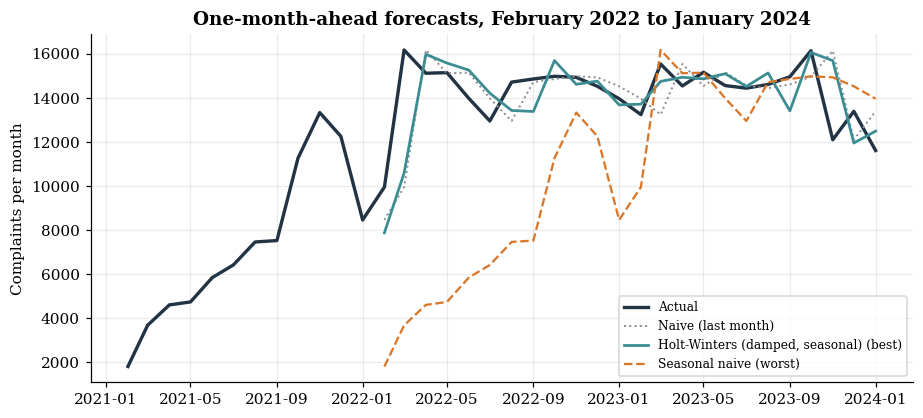

In [11]:
# Picks the best and worst model from the one-month-ahead results to plot against the actual complaints.
best_model = results_all.index[0]
worst_model = results_all.index[-1]
print("Best one-step model:", best_model, "| worst:", worst_model)

# Figure 2: one-month-ahead forecasts.
one_step_all = one_step_forecasts['All complaints']
fig, ax = plt.subplots(figsize=(8.5, 3.9))
ax.plot(y.index[-36:], y.iloc[-36:], color=NAVY, lw=2.2, label='Actual')
ax.plot(one_step_all.index, one_step_all['Naive (last month)'], color=GREY, lw=1.3, ls=':', label='Naive (last month)')
ax.plot(one_step_all.index, one_step_all[best_model], color=TEAL, lw=1.8, label=f'{best_model} (best)')
ax.plot(one_step_all.index, one_step_all[worst_model], color=ORANGE, lw=1.5, ls='--', label=f'{worst_model} (worst)')
ax.set_title('One-month-ahead forecasts, February 2022 to January 2024')
ax.set_ylabel('Complaints per month')
ax.set_xlabel('')
ax.legend(fontsize=8, loc='lower right')
plt.tight_layout()
plt.show()

## Airport Forecasting

In [12]:
# Puts each named airport's monthly complaints in its own column.
airport_wide = named.pivot(index='date', columns='airport', values='count').asfreq('MS')

# Keeps only the airports that report all 109 months.
airport_full = airport_wide[full_coverage]

# Typical monthly complaints at each airport since 2022 (the recovery).
typical = airport_full['2022-01-01':].median()

# The nationwide level across all named airports. This is used for the anomaly detection.
nat_named = airport_wide.sum(axis=1)

# Airports with a typical month of at least 10 complaints are big enough to model (109 airports).
monitorable = typical[typical >= 10].index

# For each of those airports, forecast the last 12 months with four simple models and save the error.
rows = []
for ap in monitorable:
    train = airport_full[ap].iloc[:-12]
    actual = airport_full[ap].iloc[-12:].values

    naive_pred = np.repeat(train.iloc[-1], 12)
    seasonal_pred = train.iloc[-12:].values
    avg12_pred = np.repeat(train.iloc[-12:].mean(), 12)

    # Holt-Winters needs positive numbers to be stable, so 1 is added and then taken back off.
    # If it fails for a tiny airport, the last 6 months' average is used instead.
    try:
        hw_pred = np.clip(ExponentialSmoothing(train + 1, trend='add', damped_trend=True, seasonal='add', seasonal_periods=12).fit().forecast(12).values - 1, 0, None)
    except Exception:
        hw_pred = np.repeat(train.iloc[-6:].mean(), 12)

    rows.append((ap, 'Naive (last month)', np.abs(actual - naive_pred).sum(), actual.sum()))
    rows.append((ap, 'Seasonal naive', np.abs(actual - seasonal_pred).sum(), actual.sum()))
    rows.append((ap, 'Average of last 12 months', np.abs(actual - avg12_pred).sum(), actual.sum()))
    rows.append((ap, 'Holt-Winters (damped, seasonal)', np.abs(actual - hw_pred).sum(), actual.sum()))

airport_results = pd.DataFrame(rows, columns=['airport', 'model', 'abs_err', 'actual'])

# Pooled WAPE adds up all the errors first. The median is the typical single airport.
summary = airport_results.groupby('model').agg(abs_err=('abs_err', 'sum'), actual=('actual', 'sum'))
summary['Pooled WAPE %'] = 100 * summary['abs_err'] / summary['actual']
airport_results['wape'] = 100 * airport_results['abs_err'] / airport_results['actual'].replace(0, np.nan)
summary['Median airport WAPE %'] = airport_results.groupby('model')['wape'].median()

# The plain 12-month average wins at the airport level (14.8%).
print(f"Airports modeled: {len(monitorable)} (typical monthly complaints >= 10 since 2022), 12-month holdout")
print(summary[['Pooled WAPE %', 'Median airport WAPE %']].sort_values('Pooled WAPE %').round(1))

Airports modeled: 109 (typical monthly complaints >= 10 since 2022), 12-month holdout
                                 Pooled WAPE %  Median airport WAPE %
model                                                                
Average of last 12 months                 14.8                   18.6
Holt-Winters (damped, seasonal)           17.5                   21.1
Seasonal naive                            18.3                   23.4
Naive (last month)                        18.7                   22.9


In [13]:
# How does forecast error change with airport size? Uses the 12-month average model on all 228 full-coverage airports.
tier = pd.cut(typical, [0, 5, 20, 100, np.inf], labels=['Under 5', '5 to 19', '20 to 99', '100 or more'], right=False, include_lowest=True)

tier_rows = []
for ap in airport_full.columns:
    actual = airport_full[ap].iloc[-12:].values
    prediction = np.repeat(airport_full[ap].iloc[:-12].iloc[-12:].mean(), 12)
    tier_rows.append((tier[ap], np.abs(actual - prediction).sum(), actual.sum()))

by_tier = pd.DataFrame(tier_rows, columns=['tier', 'abs_err', 'actual']).groupby('tier', observed=True).agg(
    airports=('tier', 'size'), abs_err=('abs_err', 'sum'), actual=('actual', 'sum'))
by_tier['WAPE %'] = 100 * by_tier['abs_err'] / by_tier['actual']

# Error goes from 12.6% at the biggest airports to 60.2% at the smallest ones.
print("Typical monthly complaints per airport, then forecast error:")
print(by_tier[['airports', 'WAPE %']].round(1))

Typical monthly complaints per airport, then forecast error:
             airports  WAPE %
tier                         
100 or more        30    12.6
20 to 99           54    19.5
5 to 19            64    32.0
Under 5            80    60.2


## Top Indicators

In [14]:
# The ten biggest categories by total complaints.
top_cats = category_monthly.sum().sort_values(ascending=False).head(10).index

rows = []
for cat in top_cats:

    # Month-over-month change in the log of everything except this category, and of this category.
    others_change = np.log1p(all_complaints - category_monthly[cat]).diff().dropna()
    own_change = np.log1p(category_monthly[cat]).diff().dropna()
    changes = pd.concat([others_change, own_change], axis=1).dropna()
    changes.columns = ['others', 'own']

    # Does this category help predict the rest? And does the rest help predict this category?
    forward = grangercausalitytests(changes[['others', 'own']], maxlag=3)
    reverse = grangercausalitytests(changes[['own', 'others']], maxlag=3)

    # Keeps the lag (1, 2, or 3 months) with the smallest p-value.
    forward_p = {lag: forward[lag][0]['ssr_ftest'][1] for lag in (1, 2, 3)}
    best_lag = min(forward_p, key=forward_p.get)
    reverse_p = min(reverse[lag][0]['ssr_ftest'][1] for lag in (1, 2, 3))
    rows.append((cat, best_lag, forward_p[best_lag], reverse_p))

granger = pd.DataFrame(rows, columns=['Category', 'Best lag (months)', 'p: category leads', 'p: rest leads category'])
granger['p after Bonferroni'] = (granger['p: category leads'] * len(granger)).clip(upper=1)
granger['Passes (p < 0.05)'] = granger['p after Bonferroni'] < 0.05

# Only Mishandling of Passenger Property passes (p = .021), but the rest also helps predict it (p = .012),
# so it moves with the other categories instead of ahead of them.
print(granger.round(4))

                                Category  Best lag (months)  p: category leads  p: rest leads category  p after Bonferroni  Passes (p < 0.05)
0  Expedited Passenger Screening Program                  1             0.0071                  0.2394              0.0710              False
1      Mishandling of Passenger Property                  1             0.0021                  0.0119              0.0206               True
2                       Customer Service                  3             0.0478                  0.1809              0.4781              False
3                              Screening                  1             0.9568                  0.0750              1.0000              False
4            Property - Special Handling                  1             0.5282                  0.2733              1.0000              False
5                                  Locks                  3             0.4562                  0.0008              1.0000              False
6     

## Top Indicator Visualizations

                                 Same month  1 mo earlier  2 mo earlier  3 mo earlier
Expedited Passenger Screenin...        0.79          0.17         -0.04         -0.21
Mishandling of Passenger Pro...        0.69         -0.14         -0.17         -0.06
Customer Service                       0.72         -0.00         -0.17          0.02
Screening                              0.75          0.07         -0.10         -0.12
Property - Special Handling            0.19          0.08          0.06         -0.08
Locks                                  0.75          0.08         -0.06         -0.23
Persons w/ Disabilities (PWD)          0.86          0.07         -0.16         -0.10
Patdown                                0.74          0.16         -0.14         -0.08
Civil Rights                           0.56          0.10         -0.06         -0.04
Airline                                0.47         -0.07         -0.11         -0.11


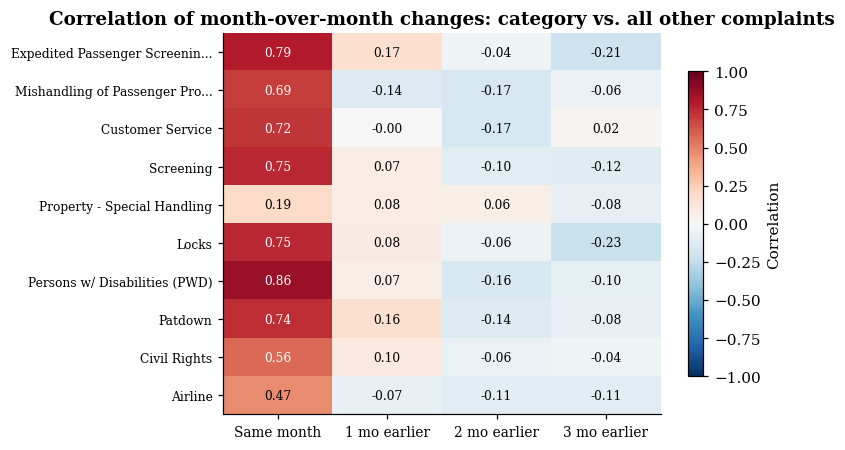

In [15]:
# For each category, how closely does its change k months earlier line up with the change in everything else this month?
lag_rows = []
lag_names = []
for cat in top_cats:
    own_change = np.log1p(category_monthly[cat]).diff()
    others_change = np.log1p(all_complaints - category_monthly[cat]).diff()
    lag_rows.append([own_change.shift(lag).corr(others_change) for lag in range(4)])
    lag_names.append(cat if len(cat) < 30 else cat[:28] + '...')

lag_corr = pd.DataFrame(lag_rows, index=lag_names, columns=['Same month', '1 mo earlier', '2 mo earlier', '3 mo earlier'])

# Categories move together in the same month (about 0.65 on average) but barely at all across months (about 0.10).
print(lag_corr.round(2))

# Figure 3: heatmap of those correlations.
fig, ax = plt.subplots(figsize=(7.2, 4.2))
im = ax.imshow(lag_corr.values, cmap='RdBu_r', vmin=-1, vmax=1, aspect='auto')
ax.set_xticks(range(4))
ax.set_xticklabels(lag_corr.columns, fontsize=9)
ax.set_yticks(range(len(lag_corr)))
ax.set_yticklabels(lag_corr.index, fontsize=8)
for i in range(lag_corr.shape[0]):
    for j in range(lag_corr.shape[1]):
        ax.text(j, i, f'{lag_corr.values[i, j]:.2f}', ha='center', va='center', fontsize=8,
                color='white' if abs(lag_corr.values[i, j]) > 0.5 else 'black')
ax.grid(False)
ax.set_title('Correlation of month-over-month changes: category vs. all other complaints')
fig.colorbar(im, ax=ax, shrink=0.8, label='Correlation')
plt.tight_layout()
plt.show()

## Category Mix Shift

In [16]:
# Labels every month as Pre, Disruption, or Recovery.
pre_mask = category_monthly.index < '2020-03-01'
period_names = np.where(pre_mask, '1 Pre (Jan 2015 - Feb 2020)',
                        np.where(category_monthly.index < '2022-01-01', '2 Disruption (Mar 2020 - Dec 2021)', '3 Recovery (Jan 2022 - Jan 2024)'))

# Each category's share of the complaints in each period.
mix = category_monthly.groupby(period_names).sum().T
share = mix / mix.sum()
share.columns = [c[2:] for c in share.columns]
share['Change, recovery vs pre (pts)'] = 100 * (share.iloc[:, 2] - share.iloc[:, 0])

# The eight biggest categories.
top8 = category_monthly.sum().sort_values(ascending=False).head(8).index
table = share.loc[top8].copy()
table.iloc[:, :3] = (100 * table.iloc[:, :3]).round(1)

# PreCheck goes from 40.4% to 79.4% of complaints and Mishandling of Passenger Property goes from 20.7% to 1.7%.
print("Share of complaints by period (%), eight largest categories:")
print(table.round(1))

months_in_period = pd.Series(period_names).value_counts().sort_index().values
print("\nComplaints per month by period:", (category_monthly.groupby(period_names).sum().sum(axis=1) / months_in_period).round(0).to_dict())

Share of complaints by period (%), eight largest categories:
                                       Pre (Jan 2015 - Feb 2020)  Disruption (Mar 2020 - Dec 2021)  Recovery (Jan 2022 - Jan 2024)  Change, recovery vs pre (pts)
clean_cat                                                                                                                                                        
Expedited Passenger Screening Program                       40.4                              59.6                            79.4                           39.1
Mishandling of Passenger Property                           20.7                               5.2                             1.7                          -19.1
Customer Service                                             8.9                               9.5                             6.2                           -2.7
Screening                                                    7.2                               6.5                             5.

In [17]:
# The pre-2020 mix of categories, as shares that add up to 1.
pre_mix = category_monthly[pre_mask].sum()
pre_mix = pre_mix / pre_mix.sum()

# Distance of each month's mix from the pre-2020 mix.
jsd_values = []
for month in category_monthly.index:
    month_mix = category_monthly.loc[month] / category_monthly.loc[month].sum()
    jsd_values.append(jensenshannon(month_mix, pre_mix, base=2))
jsd = pd.Series(jsd_values, index=category_monthly.index)

# The normal range is the 95th percentile of the distances before 2020.
band = jsd[pre_mask].quantile(0.95)
recovery = jsd['2022-01-01':]

# Every recovery month is outside the normal range, so the mix did not come back.
print(f"Pre-2020 month-to-month wobble (95th percentile of distance): {band:.3f}")
print(f"Recovery months: average distance {recovery.mean():.3f}; {(recovery > band).mean():.0%} of months sit outside the pre-2020 band")
print(f"Disruption months: average distance {jsd['2020-03-01':'2021-12-01'].mean():.3f}")

Pre-2020 month-to-month wobble (95th percentile of distance): 0.250
Recovery months: average distance 0.400; 100% of months sit outside the pre-2020 band
Disruption months: average distance 0.272


## Cateogry Mix Shift Visualizations

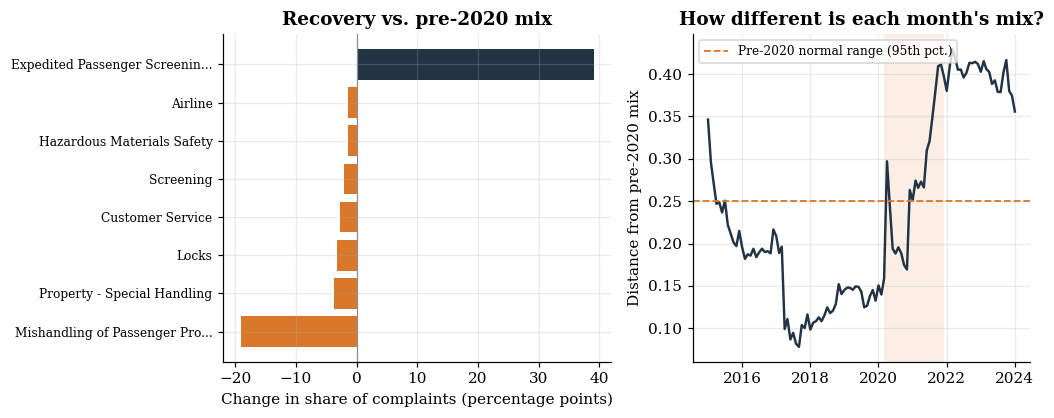

In [18]:
# Categories whose share changed by at least one point.
change = share['Change, recovery vs pre (pts)'].dropna()
change = change[change.abs() >= 1].sort_values()
change_names = [c if len(c) < 30 else c[:28] + '...' for c in change.index]

# Figure 5: left, how the mix changed. Right, how far each month is from the pre-2020 mix.
fig, axes = plt.subplots(1, 2, figsize=(9.6, 3.9), gridspec_kw={'width_ratios': [1.15, 1]})
axes[0].barh(change_names, change.values, color=[ORANGE if v < 0 else NAVY for v in change.values])
axes[0].axvline(0, color=GREY, lw=0.8)
axes[0].set_xlabel('Change in share of complaints (percentage points)')
axes[0].set_title('Recovery vs. pre-2020 mix')
axes[0].tick_params(axis='y', labelsize=8)

axes[1].plot(jsd.index, jsd.values, color=NAVY, lw=1.6)
axes[1].axhline(band, color=ORANGE, ls='--', lw=1.2, label='Pre-2020 normal range (95th pct.)')
axes[1].axvspan(pd.Timestamp('2020-03-01'), pd.Timestamp('2021-12-01'), color=ORANGE, alpha=0.12, lw=0)
axes[1].set_ylabel('Distance from pre-2020 mix')
axes[1].set_title("How different is each month's mix?")
axes[1].legend(fontsize=8, loc='upper left')
axes[1].xaxis.set_major_locator(mdates.YearLocator(2))
axes[1].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
plt.tight_layout()
plt.show()